# Task 3 — Modelos individuais e de ensemble

## 3.1 Modelos individuais

Esta secção implementa três classificadores individuais que representam princípios diferentes (linear, probabilístico e árvore de decisão), preparados para serem avaliados nos mesmos folds temporais definidos na Task 2. A escolha de cada algoritmo é justificada em relação aos dados, ao desequilíbrio de classes, aos pressupostos, à interpretabilidade e ao custo computacional.

A avaliação comparativa completa (PR-AUC, precision, recall, F1, F2 e ROC-AUC) fica para a secção seguinte. Aqui guardam-se as probabilidades previstas em cada fold, para que todas as métricas sejam calculadas a partir das mesmas previsões.

### 1. Dados, alvo e folds da Task 2

O alvo, os preditores elegíveis e os folds são reconstruídos como na Task 2 (secções 4 e 8). Os folds são comparados com `validation_protocol_task2.json`, para garantir que as divisões são exatamente as do protocolo. O teste final (a partir de 2021-08-01) não é usado nesta secção.

In [21]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", message="A worker stopped")

DATA_PATH = Path("Charging_Data_educational.csv")
protocol = json.loads(Path("validation_protocol_task2.json").read_text(encoding="utf-8"))
eligible_predictors = json.loads(Path("predictors_task2.json").read_text(encoding="utf-8"))["eligible_predictors"]

df = pd.read_csv(DATA_PATH)
df.columns = (
    df.columns.astype(str).str.strip().str.lower()
    .str.replace(r"[^a-zA-Z0-9]+", "_", regex=True).str.strip("_")
)
start_dt = pd.to_datetime(df["start_time"])
end_dt = pd.to_datetime(df["end_time"])

NORMAL_END_CAUSES = {"Charging ends normally", "User stops charging"}
y = (~df["end_cause"].isin(NORMAL_END_CAUSES)).astype(int)

CATEGORICAL = ["charging_post_id", "location_information", "district_name", "tariff_period"]


def build_features(frame):
    X = frame[eligible_predictors].copy()
    hour = start_dt.dt.hour + start_dt.dt.minute / 60
    X["hour_sin"], X["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
    X["weekday_sin"] = np.sin(2 * np.pi * start_dt.dt.weekday / 7)
    X["weekday_cos"] = np.cos(2 * np.pi * start_dt.dt.weekday / 7)
    X = X.drop(columns="start_time")
    X[CATEGORICAL] = X[CATEGORICAL].astype(str)
    numeric = [col for col in X.columns if col not in CATEGORICAL]
    X[numeric] = X[numeric].astype(float)
    return X


X = build_features(df)
numeric_cols = [col for col in X.columns if col not in CATEGORICAL]

TEST_START = pd.Timestamp(protocol["test_start"])
N_FOLDS, FOLD_MONTHS = protocol["n_folds"], protocol["fold_months"]
val_starts = [TEST_START - pd.DateOffset(months=FOLD_MONTHS * (N_FOLDS - k)) for k in range(N_FOLDS)]
val_ends = val_starts[1:] + [TEST_START]

folds = []
for v_start, v_end in zip(val_starts, val_ends):
    val_idx = np.flatnonzero(((start_dt >= v_start) & (start_dt < v_end)).to_numpy())
    train_idx = np.flatnonzero(((start_dt < v_start) & (end_dt < v_start)).to_numpy())
    folds.append((train_idx, val_idx))

for k, (tr, va) in enumerate(folds):
    expected = protocol["folds"][k]
    assert (len(tr), len(va)) == (expected["n_treino"], expected["n_validacao"]), f"fold {k + 1} difere do protocolo"
dev_mask = (start_dt < TEST_START).to_numpy()

print(f"Folds idênticos ao protocolo da Task 2: {[(len(t), len(v)) for t, v in folds]}")
print(f"Preditores: {X.shape[1]} ({len(numeric_cols)} numéricos, {len(CATEGORICAL)} categóricos) | prevalência: {y.mean():.2%}")

Folds idênticos ao protocolo da Task 2: [(79695, 66045), (145748, 57027), (202793, 42189), (244950, 64938)]
Preditores: 40 (36 numéricos, 4 categóricos) | prevalência: 18.58%


### 2. Evidência dos dados para a escolha dos modelos

Os pressupostos de cada modelo são verificados nos dados de desenvolvimento (antes de `TEST_START`), em vez de assumidos: cardinalidade das categóricas, assimetria das variáveis contínuas, valores em falta e correlação entre preditores.

In [22]:
dev = X[dev_mask]
binary_cols = [col for col in numeric_cols if col.startswith("is_") or "no_previous" in col]
continuous_cols = [col for col in numeric_cols if col not in binary_cols]

print("Cardinalidade das variáveis categóricas:")
display(dev[CATEGORICAL].nunique().rename("categorias").to_frame())

missing = dev[numeric_cols].isna().mean().rename("em_falta")
print("Colunas numéricas com valores em falta (têm indicador de ausência de histórico):")
display(missing[missing > 0].to_frame().style.format("{:.2%}"))

skew = dev[continuous_cols].skew().abs()
print(f"Variáveis contínuas: {len(continuous_cols)} | com |assimetria| > 2: {(skew > 2).sum()} "
      f"| assimetria mediana: {skew.median():.2f}")

corr = dev[continuous_cols].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = pairs[pairs >= 0.9]
print(f"Pares de variáveis contínuas com |r| >= 0.90: {len(strong)} de {len(pairs)}")
display(strong.sort_values(ascending=False).head(8).rename("|r|").to_frame())

Cardinalidade das variáveis categóricas:


,categorias
charging_post_id,92
location_information,13
district_name,3
tariff_period,7


Colunas numéricas com valores em falta (têm indicador de ausência de histórico):


,em_falta
post_hours_since_previous_completed_session,0.03%
post_hours_since_previous_completed_abnormal,0.12%
user_days_since_previous_completed_session,12.86%
user_days_since_previous_completed_abnormal,30.73%


Variáveis contínuas: 31 | com |assimetria| > 2: 17 | assimetria mediana: 2.20
Pares de variáveis contínuas com |r| >= 0.90: 4 de 465


,,|r|
user_previous_sessions_730d,user_previous_abnormal_730d,0.995905
user_previous_sessions_180d,user_previous_abnormal_180d,0.990159
user_previous_abnormal_rate_180d,user_previous_abnormal_rate_730d,0.978509
user_previous_sessions_30d,user_previous_abnormal_30d,0.964764


**Leitura.** Mais de metade das variáveis contínuas (17 de 31) tem assimetria superior a 2 (contagens de sessões e de anomalias), e há 4 pares com $|r| \geq 0{,}90$: sessões e anomalias na mesma janela do utilizador, e taxas de janelas longas do utilizador. Há valores em falta apenas nas colunas de recência, que têm indicadores de ausência de histórico. As categóricas têm cardinalidade baixa, exceto `charging_post_id` (um valor por posto).

Estes factos orientam a escolha dos modelos na secção seguinte.

### 3. Escolha e justificação dos modelos

| Princípio | Modelo | Porquê neste problema | Pressupostos e riscos | Interpretabilidade | Custo |
|---|---|---|---|---|---|
| Linear | Regressão logística (modelo de referência da Task 2) | Mistura de numéricas e categóricas resolvida com escala e *one-hot*; produz probabilidades diretamente utilizáveis no limiar por custos da secção 6 | Relação linear nos log-odds; sensível a escala e a contagens assimétricas; não capta interações (por exemplo posto × histórico) | Alta: um coeficiente por variável | Baixo |
| Probabilístico | Naive Bayes Gaussiano | Representa um princípio diferente (regra de Bayes com verosimilhança por classe) e serve de referência barata | Independência condicional dos preditores e distribuição normal por classe; os dados mostram variáveis assimétricas e alguns pares muito correlacionados, por isso os pressupostos não se verificam por completo e as probabilidades tendem a ser extremas | Média: parâmetros por classe | Muito baixo |
| Árvore de decisão | `DecisionTreeClassifier` com profundidade limitada | Capta não linearidades e interações sem pressupostos de distribuição, é insensível à escala e às contagens assimétricas e não é afetada por variáveis redundantes | Sobreajuste se crescer sem limite e instabilidade; a profundidade e `min_samples_leaf` limitam-no e evitam probabilidades de 0 ou 1 | Alta se pouco profunda: regras legíveis | Baixo |

**Alternativas não incluídas.** Os métodos baseados em instâncias (k-NN) e os de *kernel* (SVM) exigem calcular distâncias ou uma matriz de *kernel* sobre até cerca de 245 mil sessões de treino, com 4 categóricas e dezenas de contagens assimétricas, algumas redundantes, o que torna as distâncias pouco informativas e o custo elevado. Com três princípios bem justificados, não se acrescentam mais algoritmos.

**Desequilíbrio de classes.** A classe anormal representa cerca de 18,6% das sessões, um desequilíbrio moderado. Não se usa reponderação nem *resampling*: a métrica principal (PR-AUC) depende apenas da ordenação das probabilidades, e o limiar por custos definido na Task 2 ($1/(1+4)$) assume probabilidades coerentes com a prevalência real, o que a reponderação alteraria. O limiar é tratado na avaliação.

**Regra de seleção de hiperparâmetros.** Só dois pontos são ajustados, e apenas com os folds de validação: a profundidade da árvore e a inclusão de `charging_post_id` no Naive Bayes. O teste final não é usado.

### 4. Implementação

Cada modelo tem o pré-processamento adequado aos seus pressupostos, ajustado dentro do `Pipeline` apenas com o treino de cada fold:

- **Regressão logística:** mediana + padronização nas numéricas e *one-hot* nas categóricas (igual ao modelo de referência da Task 2).
- **Naive Bayes:** mediana nas numéricas (o modelo é invariante à escala) e *one-hot* denso nas categóricas.
- **Árvore:** mediana nas numéricas e codificação ordinal nas categóricas (a árvore parte por limiares e dispensa *one-hot*).

In [23]:
RANDOM_STATE = 42
TREE_MIN_SAMPLES_LEAF = 200


def numeric_scaled():
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])


def make_logistic():
    prep = ColumnTransformer([
        ("num", numeric_scaled(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATEGORICAL),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))])


def make_naive_bayes(with_post_id=False):
    categorical = CATEGORICAL if with_post_id else [col for col in CATEGORICAL if col != "charging_post_id"]
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False), categorical),
    ])
    return Pipeline([("prep", prep), ("clf", GaussianNB())])


def make_tree(max_depth):
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL),
    ])
    clf = DecisionTreeClassifier(
        max_depth=max_depth, min_samples_leaf=TREE_MIN_SAMPLES_LEAF, random_state=RANDOM_STATE
    )
    return Pipeline([("prep", prep), ("clf", clf)])


def cross_val_predict_folds(make_model):
    """Probabilidade da classe anormal em cada fold de validação, com ajuste só no treino do fold."""
    predictions, fit_seconds = [], []
    for train_idx, val_idx in folds:
        started = time.perf_counter()
        model = make_model().fit(X.iloc[train_idx], y.iloc[train_idx])
        fit_seconds.append(time.perf_counter() - started)
        predictions.append(model.predict_proba(X.iloc[val_idx])[:, 1])
    return {"pred": predictions, "fit_s": float(np.mean(fit_seconds))}


def pr_auc_by_fold(result):
    return [average_precision_score(y.iloc[va], p) for (_, va), p in zip(folds, result["pred"])]

### 5. Hiperparâmetros: profundidade da árvore e Naive Bayes com e sem `charging_post_id`

A profundidade da árvore é escolhida como a **menor** profundidade cuja PR-AUC média está a menos de 0,003 da melhor (a mesma tolerância por fold usada na secção 8.7b da Task 2), para preferir a árvore mais simples e legível quando o ganho é dentro do ruído. A PR-AUC é usada aqui só para escolher; a comparação completa entre modelos fica para a secção seguinte.

In [24]:
TREE_DEPTHS = (3, 5, 8, 12, 16)
DEPTH_TOLERANCE = 0.003

tree_results = {depth: cross_val_predict_folds(lambda d=depth: make_tree(d)) for depth in TREE_DEPTHS}
tree_table = pd.DataFrame({
    depth: {**{f"fold {k + 1}": s for k, s in enumerate(pr_auc_by_fold(r))}, "média": np.mean(pr_auc_by_fold(r)),
            "tempo de ajuste por fold (s)": r["fit_s"]}
    for depth, r in tree_results.items()
}).T
tree_table.index.name = "max_depth"

best_mean = tree_table["média"].max()
chosen_depth = min(d for d in TREE_DEPTHS if tree_table.loc[d, "média"] >= best_mean - DEPTH_TOLERANCE)
print(f"Árvore de decisão (min_samples_leaf={TREE_MIN_SAMPLES_LEAF}): PR-AUC por profundidade")
display(tree_table.round(4))
print(f"Profundidade escolhida: {chosen_depth}")

nb_variants = {
    "sem charging_post_id": cross_val_predict_folds(lambda: make_naive_bayes(with_post_id=False)),
    "com charging_post_id": cross_val_predict_folds(lambda: make_naive_bayes(with_post_id=True)),
}
nb_table = pd.DataFrame({
    name: {**{f"fold {k + 1}": s for k, s in enumerate(pr_auc_by_fold(r))}, "média": np.mean(pr_auc_by_fold(r))}
    for name, r in nb_variants.items()
}).T
print("\nNaive Bayes: PR-AUC com e sem o identificador do posto")
display(nb_table.round(4))
use_post_id_in_nb = bool(nb_table.loc["com charging_post_id", "média"] > nb_table.loc["sem charging_post_id", "média"])
print(f"charging_post_id no Naive Bayes: {'incluído' if use_post_id_in_nb else 'excluído'}")

Árvore de decisão (min_samples_leaf=200): PR-AUC por profundidade


,fold 1,fold 2,fold 3,fold 4,média,tempo de ajuste por fold (s)
max_depth,,,,,,
3,0.5315,0.4932,0.4165,0.5663,0.5019,1.5246
5,0.5967,0.5612,0.4806,0.6225,0.5652,2.1494
8,0.6210,0.5952,0.5155,0.6545,0.5966,2.9196
12,0.6230,0.5976,0.5193,0.6546,0.5986,3.5671
16,0.6226,0.5981,0.5169,0.6543,0.5980,3.9995


Profundidade escolhida: 8

Naive Bayes: PR-AUC com e sem o identificador do posto


,fold 1,fold 2,fold 3,fold 4,média
sem charging_post_id,0.5369,0.527,0.4439,0.5610,0.5172
com charging_post_id,0.4013,0.405,0.3468,0.4524,0.4014


charging_post_id no Naive Bayes: excluído


### 6. Modelos finais e previsões por fold

Os três modelos ficam com a configuração escolhida e as probabilidades de cada fold são guardadas em `individual_models`, para a secção de avaliação. A tabela confirma que os três foram ajustados nos mesmos folds e mostra o custo computacional de cada um.

In [25]:
individual_models = {
    "Regressão logística": cross_val_predict_folds(make_logistic),
    "Naive Bayes": nb_variants["com charging_post_id" if use_post_id_in_nb else "sem charging_post_id"],
    f"Árvore de decisão (profundidade {chosen_depth})": tree_results[chosen_depth],
}

for name, result in individual_models.items():
    assert [len(p) for p in result["pred"]] == [len(va) for _, va in folds], name
    assert all(np.isfinite(p).all() and p.min() >= 0 and p.max() <= 1 for p in result["pred"]), name

overview = pd.DataFrame({
    "princípio": ["Linear", "Probabilístico", "Árvore de decisão"],
    "folds ajustados": [len(r["pred"]) for r in individual_models.values()],
    "tempo de ajuste por fold (s)": [r["fit_s"] for r in individual_models.values()],
    "probabilidade prevista mínima": [min(p.min() for p in r["pred"]) for r in individual_models.values()],
    "probabilidade prevista máxima": [max(p.max() for p in r["pred"]) for r in individual_models.values()],
}, index=list(individual_models))
display(overview.round(4))

,princípio,folds ajustados,tempo de ajuste por fold (s),probabilidade prevista mínima,probabilidade prevista máxima
Regressão logística,Linear,4,5.1915,0.0025,0.9986
Naive Bayes,Probabilístico,4,0.8934,0.0000,1.0000
Árvore de decisão (profundidade 8),Árvore de decisão,4,2.9196,0.0132,1.0000


### 7. Interpretabilidade

Para verificar a interpretabilidade invocada na escolha, mostram-se as variáveis mais influentes da regressão logística (maiores coeficientes em valor absoluto, em variáveis padronizadas) e da árvore (importância por redução de impureza), ajustadas no treino do último fold. É apenas uma leitura de um fold, não uma análise de importância.

In [26]:
train_idx_last = folds[-1][0]

logistic = make_logistic().fit(X.iloc[train_idx_last], y.iloc[train_idx_last])
logistic_names = logistic.named_steps["prep"].get_feature_names_out()
coefficients = pd.Series(logistic.named_steps["clf"].coef_[0], index=logistic_names)
print("Regressão logística: 8 maiores coeficientes em valor absoluto")
display(coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(8).rename("coeficiente").to_frame().round(3))

tree = make_tree(chosen_depth).fit(X.iloc[train_idx_last], y.iloc[train_idx_last])
tree_names = tree.named_steps["prep"].get_feature_names_out()
importances = pd.Series(tree.named_steps["clf"].feature_importances_, index=tree_names).sort_values(ascending=False)
print("Árvore de decisão: 8 variáveis com maior importância")
display(importances.head(8).rename("importância").to_frame().round(3))

Regressão logística: 8 maiores coeficientes em valor absoluto


,coeficiente
num__user_previous_abnormal_730d,-0.571
num__user_previous_sessions_730d,0.508
num__post_previous_abnormal_rate_1d,0.449
cat__charging_post_id_54,0.416
num__post_previous_abnormal_rate_7d,0.410
cat__district_name_Tongxiang,-0.391
num__user_previous_abnormal_rate_730d,0.355
cat__charging_post_id_43,0.334


Árvore de decisão: 8 variáveis com maior importância


,importância
num__post_previous_abnormal_rate_1d,0.543
num__user_days_since_previous_completed_abnormal,0.180
num__post_previous_abnormal_rate_30d,0.081
num__post_previous_abnormal_rate_7d,0.049
num__post_hours_since_previous_completed_abnormal,0.047
num__user_previous_abnormal_rate_730d,0.033
num__user_previous_abnormal_rate_30d,0.020
num__post_previous_sessions_1d,0.013


### 8. Resumo da secção 3.1

- **Modelos implementados:** regressão logística (linear), Naive Bayes Gaussiano (probabilístico) e árvore de decisão, ajustados nos mesmos 4 folds temporais da Task 2. As probabilidades de validação ficam em `individual_models`, prontas para a avaliação.
- **Árvore de decisão:** a PR-AUC média estabiliza a partir da profundidade 8 (0,597 contra 0,599 com profundidade 12), pelo que se escolhe 8, mais simples e legível.
- **Naive Bayes:** incluir `charging_post_id` por *one-hot* baixa a PR-AUC média de 0,517 para 0,402, por isso fica de fora. Os 92 indicadores de posto repetem informação que o histórico do posto já traz e agravam a violação da independência condicional.
- **Custo computacional:** o ajuste demora entre 0,6 s e 1,8 s por fold nos três modelos, pelo que o custo não distingue os modelos neste problema.
- **Probabilidades:** o Naive Bayes produz probabilidades que chegam a 0 e a 1. Isto, e o uso do limiar 0,2 da Task 2, deve ser verificado na avaliação (por exemplo, com a calibração).
- **Interpretabilidade:** nos dois modelos legíveis, a taxa de anomalias recente do posto (`post_previous_abnormal_rate_1d`) é das variáveis mais influentes: a maior importância na árvore (0,54) e o segundo maior coeficiente em valor absoluto na regressão logística. A árvore dá ainda peso ao tempo desde a última anomalia do utilizador, o que é coerente com a ablação por grupos da Task 2, em que só o histórico do posto e do utilizador contribuíam de forma mensurável.

**Limitações.** A profundidade da árvore e a decisão sobre `charging_post_id` no Naive Bayes foram escolhidas nos mesmos folds em que depois se avalia, o que torna a comparação ligeiramente otimista; o teste final continua intocado. A leitura de coeficientes e importâncias vem de um único fold. Cada princípio é representado por um só algoritmo.

## 3.2 Avaliação individual

Os três modelos são avaliados **nas mesmas previsões e nos mesmos folds**, a partir de `individual_models`. A métrica principal é a PR-AUC (*average precision*), que depende apenas da ordenação das probabilidades e não do limiar. Precision, recall, F1 e F2 dependem do limiar e usam o valor provisório da Task 2 (0,2, correspondente a um custo de falso negativo 4 vezes o de falso positivo); a ROC-AUC é secundária. A accuracy não é usada, porque com 18,6% de sessões anormais um modelo que prevê sempre "normal" já a tem alta. O Brier score acrescenta-se como verificação das probabilidades, o que interessa porque o limiar é fixo.

Como referência incluem-se os dois baselines do protocolo: a prevalência (PR-AUC igual à fração de anómalas) e a taxa histórica de anomalias do posto nos últimos 30 dias. Um modelo só é útil se superar o segundo.

In [27]:
from sklearn.metrics import brier_score_loss, f1_score, fbeta_score, precision_score, recall_score, roc_auc_score

THRESHOLD = protocol["threshold_provisional"]
METRICS = ["PR-AUC (AP)", "Precision", "Recall", "F1", "F2", "ROC-AUC", "Brier", "Alertas por 1000"]
LOWER_IS_BETTER = {"Brier"}


def evaluate_fold(y_true, score, threshold=THRESHOLD):
    alert = (score >= threshold).astype(int)
    return {
        "PR-AUC (AP)": average_precision_score(y_true, score),
        "Precision": precision_score(y_true, alert, zero_division=0),
        "Recall": recall_score(y_true, alert, zero_division=0),
        "F1": f1_score(y_true, alert, zero_division=0),
        "F2": fbeta_score(y_true, alert, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, score),
        "Brier": brier_score_loss(y_true, score),
        "Alertas por 1000": 1000 * alert.mean(),
    }


rows = []
for model_name, result in individual_models.items():
    for k, ((_, val_idx), score) in enumerate(zip(folds, result["pred"]), start=1):
        rows.append({"modelo": model_name, "fold": k, **evaluate_fold(y.iloc[val_idx].to_numpy(), score)})
per_fold = pd.DataFrame(rows)

history_score = df["post_previous_abnormal_rate_30d"].fillna(0).to_numpy()
baselines = pd.DataFrame({
    f"fold {k}": {
        "Baseline prevalência (PR-AUC)": y.iloc[va].mean(),
        "Baseline histórico do posto 30d (PR-AUC)": average_precision_score(y.iloc[va], history_score[va]),
    }
    for k, (_, va) in enumerate(folds, start=1)
}).T
baseline_means = baselines.mean()

### 1. Resultados por fold

In [28]:
display(per_fold.set_index(["modelo", "fold"]).round(4))
print("PR-AUC dos baselines por fold:")
display(baselines.T.round(4))

PR-AUC (AP)  Precision  Recall  \
modelo                             fold                                   
Regressão logística                1          0.6153     0.4692  0.6653   
                                   2          0.5776     0.4344  0.6006   
                                   3          0.5011     0.3991  0.5869   
                                   4          0.6356     0.4877  0.6667   
Naive Bayes                        1          0.5369     0.4689  0.6186   
                                   2          0.5270     0.4539  0.5160   
                                   3          0.4439     0.3884  0.4928   
                                   4          0.5610     0.4381  0.6656   
Árvore de decisão (profundidade 8) 1          0.6210     0.4896  0.6623   
                                   2          0.5952     0.4822  0.5870   
                                   3          0.5155     0.4249  0.5477   
                                   4          0.6545     0.4780  0.6858   

                                             F1      F2  ROC-AUC   Brier  \
modelo                             fold                                    
Regressão logística                1     0.5503  0.6139   0.8273  0.1070   
                                   2     0.5041  0.5579   0.8150  0.1023   
                                   3     0.4751  0.5364   0.8067  0.1011   
                                   4     0.5633  0.6211   0.8340  0.1079   
Naive Bayes                        1     0.5335  0.5815   0.7942  0.1771   
                                   2     0.4829  0.5022   0.7809  0.1587   
                                   3     0.4344  0.4677   0.7724  0.1654   
                                   4     0.5284  0.6030   0.8020  0.1977   
Árvore de decisão (profundidade 8) 1     0.5630  0.6187   0.8298  0.1049   
                                   2     0.5295  0.5625   0.8233  0.0991   
                                   3     0.4786  0.5178   0.8094  0.0995   
                                   4     0.5634  0.6310   0.8398  0.1049   

                                         Alertas por 1000  
modelo                             fold                    
Regressão logística                1             264.8800  
                                   2             232.1707  
                                   3             225.2720  
                                   4             265.6996  
Naive Bayes                        1             246.4229  
                                   2             190.8920  
                                   3             194.3872  
                                   4             295.2355  
Árvore de decisão (profundidade 8) 1             252.7216  
                                   2             204.4119  
                                   3             197.4685  
                                   4             278.8044

PR-AUC dos baselines por fold:


,fold 1,fold 2,fold 3,fold 4
Baseline prevalência (PR-AUC),0.1868,0.1679,0.1532,0.1943
Baseline histórico do posto 30d (PR-AUC),0.4604,0.4387,0.3617,0.4688


### 2. Tabela comparativa (média, desvio-padrão e pior fold)

Média simples dos 4 folds com desvio-padrão; o pior fold é o menor valor nas métricas em que mais é melhor e o maior no Brier score. Com 4 folds, o desvio-padrão é indicativo.

In [29]:
grouped = per_fold.groupby("modelo")

mean_table = grouped[METRICS].mean()
std_table = grouped[METRICS].std(ddof=1)

worst_table = pd.DataFrame({
    m: grouped[m].max() if m in LOWER_IS_BETTER else grouped[m].min()
    for m in METRICS
    if m != "Alertas por 1000"
})


# Compatibilidade entre diferentes versões do pandas:
# - pandas >= 2.1: DataFrame.map()
# - pandas < 2.1: DataFrame.applymap()
def df_format_3(df):
    if hasattr(df, "map"):
        return df.map("{:.3f}".format)
    return df.applymap("{:.3f}".format)


comparison = (
    df_format_3(mean_table)
    + " ("
    + df_format_3(std_table)
    + ")"
)

comparison = comparison.loc[
    mean_table["PR-AUC (AP)"].sort_values(ascending=False).index
]

print("Média (desvio-padrão) por modelo, ordenado pela PR-AUC média:")
display(comparison)

print("Pior fold por modelo:")
display(worst_table.loc[comparison.index].round(4))

print(
    f"PR-AUC média dos baselines: "
    f"prevalência = {baseline_means.iloc[0]:.3f} | "
    f"histórico do posto 30d = {baseline_means.iloc[1]:.3f}"
)

Média (desvio-padrão) por modelo, ordenado pela PR-AUC média:


,PR-AUC (AP),Precision,Recall,F1,F2,ROC-AUC,Brier,Alertas por 1000
modelo,,,,,,,,
Árvore de decisão (profundidade 8),0.597 (0.059),0.469 (0.030),0.621 (0.064),0.534 (0.040),0.582 (0.052),0.826 (0.013),0.102 (0.003),233.352 (39.014)
Regressão logística,0.582 (0.059),0.448 (0.039),0.630 (0.042),0.523 (0.041),0.582 (0.042),0.821 (0.012),0.105 (0.003),247.006 (21.302)
Naive Bayes,0.517 (0.051),0.437 (0.035),0.573 (0.082),0.495 (0.046),0.539 (0.064),0.787 (0.013),0.175 (0.017),231.734 (49.366)


Pior fold por modelo:


,PR-AUC (AP),Precision,Recall,F1,F2,ROC-AUC,Brier
modelo,,,,,,,
Árvore de decisão (profundidade 8),0.5155,0.4249,0.5477,0.4786,0.5178,0.8094,0.1049
Regressão logística,0.5011,0.3991,0.5869,0.4751,0.5364,0.8067,0.1079
Naive Bayes,0.4439,0.3884,0.4928,0.4344,0.4677,0.7724,0.1977


PR-AUC média dos baselines: prevalência = 0.176 | histórico do posto 30d = 0.432


### 3. Consistência entre períodos e diferenças entre modelos

A ordenação dos modelos em cada fold e a diferença emparelhada de PR-AUC (mesmo fold, mesmo conjunto de validação) mostram se uma vantagem média é consistente ou se vem de um só período.

In [30]:
pr_by_model = per_fold.pivot(index="fold", columns="modelo", values="PR-AUC (AP)")
print("PR-AUC por fold:")
display(pr_by_model.round(4))
print("Posição de cada modelo em cada fold (1 = melhor PR-AUC):")
display(pr_by_model.rank(axis=1, ascending=False).astype(int))

tree_name = next(name for name in pr_by_model.columns if name.startswith("Árvore"))
diff_tree_logistic = (pr_by_model[tree_name] - pr_by_model["Regressão logística"]).rename("árvore - regressão logística")
print("Diferença emparelhada de PR-AUC (árvore menos regressão logística):")
display(diff_tree_logistic.round(4).to_frame().T)
print(f"Média: {diff_tree_logistic.mean():.4f} | folds em que a árvore é melhor: {(diff_tree_logistic > 0).sum()} de {len(diff_tree_logistic)}")

PR-AUC por fold:


modelo,Naive Bayes,Regressão logística,Árvore de decisão (profundidade 8)
fold,,,
1,0.5369,0.6153,0.6210
2,0.5270,0.5776,0.5952
3,0.4439,0.5011,0.5155
4,0.5610,0.6356,0.6545


Posição de cada modelo em cada fold (1 = melhor PR-AUC):


modelo,Naive Bayes,Regressão logística,Árvore de decisão (profundidade 8)
fold,,,
1,3,2,1
2,3,2,1
3,3,2,1
4,3,2,1


Diferença emparelhada de PR-AUC (árvore menos regressão logística):


fold,1,2,3,4
árvore - regressão logística,0.0057,0.0176,0.0144,0.019


Média: 0.0142 | folds em que a árvore é melhor: 4 de 4


### 4. Sensibilidade ao limiar

Precision, recall, F1 e F2 dependem do limiar, e o 0,2 é provisório. A tabela mostra como a média entre folds varia com o limiar, para ver se a comparação entre modelos depende dessa escolha. Não se escolhe aqui um limiar.

In [31]:
THRESHOLDS = (0.1, 0.2, 0.3, 0.4, 0.5)
sensitivity_rows = []
for model_name, result in individual_models.items():
    for threshold in THRESHOLDS:
        fold_values = [
            evaluate_fold(y.iloc[va].to_numpy(), score, threshold)
            for (_, va), score in zip(folds, result["pred"])
        ]
        sensitivity_rows.append({
            "modelo": model_name, "limiar": threshold,
            **{m: np.mean([v[m] for v in fold_values]) for m in ("Precision", "Recall", "F2", "Alertas por 1000")},
        })
sensitivity = pd.DataFrame(sensitivity_rows).set_index(["modelo", "limiar"])
display(sensitivity.round(3))

Precision  Recall     F2  \
modelo                             limiar                             
Regressão logística                0.1         0.306   0.842  0.623   
                                   0.2         0.448   0.630  0.582   
                                   0.3         0.563   0.498  0.510   
                                   0.4         0.662   0.408  0.441   
                                   0.5         0.741   0.342  0.382   
Naive Bayes                        0.1         0.423   0.597  0.551   
                                   0.2         0.437   0.573  0.539   
                                   0.3         0.447   0.558  0.530   
                                   0.4         0.455   0.547  0.525   
                                   0.5         0.463   0.537  0.519   
Árvore de decisão (profundidade 8) 0.1         0.294   0.867  0.623   
                                   0.2         0.469   0.621  0.582   
                                   0.3         0.579   0.516  0.526   
                                   0.4         0.650   0.454  0.482   
                                   0.5         0.731   0.382  0.421   

                                           Alertas por 1000  
modelo                             limiar                    
Regressão logística                0.1              482.644  
                                   0.2              247.006  
                                   0.3              155.533  
                                   0.4              109.186  
                                   0.5               82.105  
Naive Bayes                        0.1              249.234  
                                   0.2              231.734  
                                   0.3              220.800  
                                   0.4              212.712  
                                   0.5              205.426  
Árvore de decisão (profundidade 8) 0.1              518.581  
                                   0.2              233.352  
                                   0.3              157.594  
                                   0.4              124.625  
                                   0.5               92.789

### 5. Gráfico: PR-AUC por fold

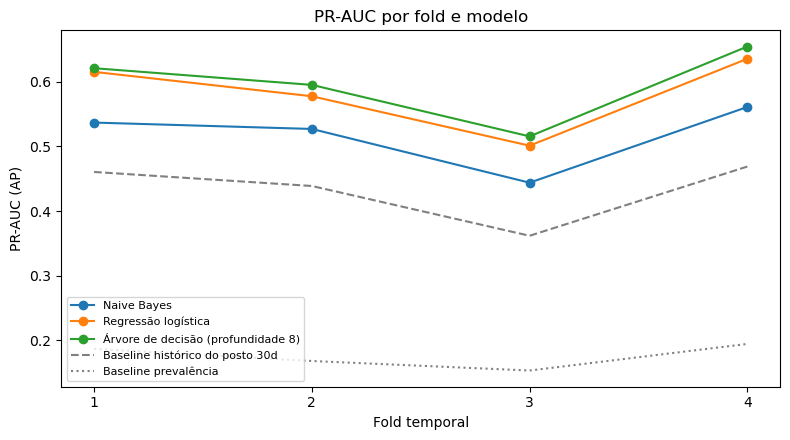

In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
for model_name in pr_by_model.columns:
    ax.plot(pr_by_model.index, pr_by_model[model_name], marker="o", label=model_name)
ax.plot(baselines.index.str.replace("fold ", "").astype(int), baselines["Baseline histórico do posto 30d (PR-AUC)"],
        ls="--", color="gray", label="Baseline histórico do posto 30d")
ax.plot(baselines.index.str.replace("fold ", "").astype(int), baselines["Baseline prevalência (PR-AUC)"],
        ls=":", color="gray", label="Baseline prevalência")
ax.set(xlabel="Fold temporal", ylabel="PR-AUC (AP)", title="PR-AUC por fold e modelo", xticks=list(pr_by_model.index))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 6. Conclusões da avaliação individual

A tabela reúne a evidência principal por modelo e a figura mostra como o limiar muda o compromisso entre recall e precision e o volume de alertas. As conclusões seguem-se.

In [33]:
validation_prevalence = float(np.mean([y.iloc[va].mean() for _, va in folds]))
history_baseline = baseline_means["Baseline histórico do posto 30d (PR-AUC)"]

summary = pd.DataFrame({
    "PR-AUC média": mean_table["PR-AUC (AP)"],
    "PR-AUC pior fold": worst_table["PR-AUC (AP)"],
    "Ganho sobre o baseline do histórico": mean_table["PR-AUC (AP)"] - history_baseline,
    "Precision (0,2)": mean_table["Precision"],
    "Recall (0,2)": mean_table["Recall"],
    "F2 (0,2)": mean_table["F2"],
    "Brier": mean_table["Brier"],
    "Alertas por 1000 (0,2)": mean_table["Alertas por 1000"],
}).sort_values("PR-AUC média", ascending=False)

display(
    summary.style
    .format("{:.3f}", subset=[col for col in summary.columns if not col.startswith("Alertas")])
    .format("{:.0f}", subset=["Alertas por 1000 (0,2)"])
    .highlight_max(axis=0, color="#d4edda", subset=[col for col in summary.columns if col not in ("Brier", "Alertas por 1000 (0,2)")])
    .highlight_min(axis=0, color="#d4edda", subset=["Brier"])
)
print(f"Verde = melhor valor da coluna. Referência: baseline do histórico = {history_baseline:.3f} (PR-AUC) | "
      f"anomalias reais = {validation_prevalence * 1000:.0f} por 1000 sessões.")

,PR-AUC média,PR-AUC pior fold,Ganho sobre o baseline do histórico,"Precision (0,2)","Recall (0,2)","F2 (0,2)",Brier,"Alertas por 1000 (0,2)"
modelo,,,,,,,,
Árvore de decisão (profundidade 8),0.597,0.516,0.164,0.469,0.621,0.582,0.102,233
Regressão logística,0.582,0.501,0.150,0.448,0.630,0.582,0.105,247
Naive Bayes,0.517,0.444,0.085,0.437,0.573,0.539,0.175,232


Verde = melhor valor da coluna. Referência: baseline do histórico = 0.432 (PR-AUC) | anomalias reais = 176 por 1000 sessões.


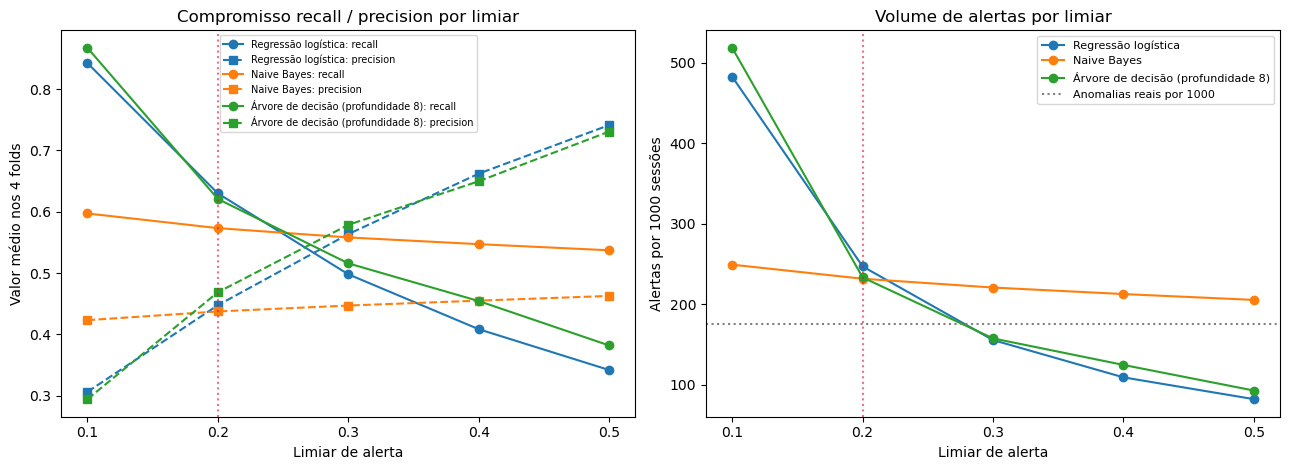

In [34]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colors = dict(zip(individual_models, ["tab:blue", "tab:orange", "tab:green"]))

for model_name, color in colors.items():
    data = sensitivity.loc[model_name]
    axes[0].plot(data.index, data["Recall"], color=color, marker="o", label=f"{model_name}: recall")
    axes[0].plot(data.index, data["Precision"], color=color, marker="s", ls="--", label=f"{model_name}: precision")
    axes[1].plot(data.index, data["Alertas por 1000"], color=color, marker="o", label=model_name)

axes[0].set(title="Compromisso recall / precision por limiar", xlabel="Limiar de alerta", ylabel="Valor médio nos 4 folds")
axes[1].axhline(validation_prevalence * 1000, color="gray", ls=":", label="Anomalias reais por 1000")
axes[1].set(title="Volume de alertas por limiar", xlabel="Limiar de alerta", ylabel="Alertas por 1000 sessões")
for ax in axes:
    ax.axvline(THRESHOLD, color="crimson", ls=":", alpha=0.6)
    ax.set_xticks(list(THRESHOLDS))
axes[0].legend(fontsize=7, ncol=1)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

- **Todos superam os baselines.** Os três modelos ficam acima da prevalência (PR-AUC média 0,176) e do histórico do posto a 30 dias (0,432) em todos os folds. Este segundo baseline é o relevante: a regressão logística e a árvore ficam cerca de 0,15 acima dele em PR-AUC média, o Naive Bayes cerca de 0,09.
- **Ordenação estável.** Pela PR-AUC, a árvore (0,597) está à frente da regressão logística (0,582) e esta do Naive Bayes (0,517) nos 4 folds. A vantagem da árvore sobre a regressão logística é pequena (média 0,014, entre 0,005 e 0,019 por fold) mas tem o mesmo sinal em todos os folds. A variação entre períodos (desvio-padrão de cerca de 0,06) é maior do que a diferença entre os dois melhores modelos, por isso a diferença deve ser lida como um indício, não como uma separação clara. O fold 3, com a menor prevalência (0,153), é o mais difícil para todos, e o fold 4 o mais fácil.
- **Com o limiar 0,2 a árvore e a regressão logística são equivalentes.** O F2 médio é igual (0,582). A regressão logística tem mais recall (0,630 contra 0,621) e a árvore mais precision (0,469 contra 0,447); no pior fold, o F2 é melhor na regressão logística (0,536 contra 0,518). A ROC-AUC, secundária, vai no mesmo sentido da PR-AUC (0,826, 0,821 e 0,787). A diferença em PR-AUC não se traduz, a este limiar, numa diferença em F2.
- **O Naive Bayes tem as probabilidades menos fiáveis.** Tem o pior resultado em todas as métricas e um Brier score de 0,175, contra 0,102 e 0,105 nos outros dois. Com o limiar a variar de 0,1 a 0,5, os seus alertas só passam de 249 para 205 por 1000 sessões, enquanto na regressão logística e na árvore passam de cerca de 500 para menos de 100: as probabilidades concentram-se perto de 0 e 1, e o limiar quase não controla o volume de alertas. Isto confirma a violação dos pressupostos apontada na secção 3.1.
- **O limiar condiciona o compromisso.** A 0,1, a regressão logística e a árvore têm recall de 0,84 a 0,87, mas sinalizam cerca de metade das sessões (483 a 519 alertas por 1000, contra cerca de 176 anómalas por 1000 nos folds de validação). A 0,2 sinalizam 233 a 247 por 1000. O limiar final deve ser escolhido com os folds de validação e a razão de custos validada com a operação.
- **A accuracy não foi usada**, porque com 18,6% de sessões anormais não distingue modelos úteis de um que prevê sempre a classe normal.

**Limitações.** A profundidade da árvore foi escolhida nos mesmos folds em que se avalia, por isso a vantagem da árvore pode estar ligeiramente sobrestimada. Com 4 folds, os desvios-padrão e o pior fold são indicativos. Precision, recall, F1 e F2 dependem do limiar provisório de 0,2. Cada princípio é representado por um só algoritmo.

**Para a comparação com os ensembles.** As previsões e métricas por fold estão em `individual_models` e `per_fold`, no mesmo formato e nos mesmos folds, para comparar diretamente com a Random Forest e o *boosting*. A referência a superar é a árvore (PR-AUC média 0,597), com a regressão logística (0,582) como alternativa mais simples.

## 3.3 Ablação por grupos de variáveis

Esta secção mede quanto cada grupo de preditores contribui para detetar sessões anormais. Usam-se a regressão logística e a árvore de decisão (profundidade escolhida na secção 5), com os mesmos folds temporais, os mesmos hiperparâmetros e a mesma preparação de dados. Só muda o conjunto de colunas. O Naive Bayes fica de fora por ser o modelo mais fraco na secção 3.2 e para manter a ablação simples.

Os grupos derivam dos da Task 2 (secção 8.7b) e os conjuntos crescem por camadas:

| Conjunto | Grupos | Pergunta a que responde |
|---|---|---|
| A | local, hora e dia da semana, meteorologia | Que desempenho se obtém sem qualquer histórico? |
| B | A + tarifa | A tarifa acrescenta algo para além da hora do dia? |
| C | B + histórico do posto | Quanto vale o histórico do posto? |
| D | C + histórico do utilizador | O histórico do utilizador acrescenta algo ao do posto? |
| D sem ID | D sem `charging_post_id` | O modelo depende da identidade do posto? |

A hora e o dia da semana estão em A porque o período tarifário depende em grande parte deles. Assim, a diferença B - A mede o efeito da tarifa para além do momento do dia. O conjunto A já inclui `charging_post_id`, por isso o modelo consegue aprender a taxa média de anomalias de cada posto. Quando o histórico do posto entra em C, o ganho mede apenas o que o estado recente do posto traz para além disso.

Aqui, os quatro grupos de utilizador da Task 2 (histórico, recência, sessões ativas e utilizador novo) ficam juntos em `historico_utilizador`, e o histórico e a recência do posto ficam juntos em `historico_posto`. A métrica principal é a PR-AUC, como no protocolo. As diferenças são calculadas por fold, com o mesmo modelo, para ver se o efeito é consistente no tempo.

In [35]:
GROUPS = {
    "local": ["charging_post_id", "location_information", "district_name"],
    "hora_semana": ["hour_sin", "hour_cos", "weekday_sin", "weekday_cos"],
    "meteorologia": ["temperature", "relative_humidity", "precipitation_mm"],
    "tarifa": ["electricity_price", "tariff_period"],
    "historico_posto": [
        c for c in X.columns if c.startswith(("post_previous_", "post_hours_since", "post_no_previous"))
    ],
    "historico_utilizador": [
        c for c in X.columns
        if c.startswith(("user_previous_", "user_days_since", "user_no_previous", "user_active_sessions"))
    ] + ["is_new_user"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(X.columns), "Há colunas sem grupo ou repetidas"

ABLATION_GROUPS = {
    "A": ["local", "hora_semana", "meteorologia"],
    "B": ["local", "hora_semana", "meteorologia", "tarifa"],
    "C": ["local", "hora_semana", "meteorologia", "tarifa", "historico_posto"],
    "D": list(GROUPS),
}


def columns_of(group_names):
    return [c for c in X.columns if any(c in GROUPS[g] for g in group_names)]


variants = {name: columns_of(groups) for name, groups in ABLATION_GROUPS.items()}
variants["D sem ID"] = [c for c in variants["D"] if c != "charging_post_id"]

description = pd.DataFrame({
    "conjunto": list(variants),
    "grupos": ["contexto (local + hora/dia da semana) + meteorologia", "A + tarifa", "B + histórico do posto",
               "C + histórico do utilizador", "D sem o identificador do posto"],
    "nº colunas": [len(v) for v in variants.values()],
}).set_index("conjunto")
display(description)
print({g: len(cols) for g, cols in GROUPS.items()})

,grupos,nº colunas
conjunto,,
A,contexto (local + hora/dia da semana) + meteor...,10
B,A + tarifa,12
C,B + histórico do posto,25
D,C + histórico do utilizador,40
D sem ID,D sem o identificador do posto,39


{'local': 3, 'hora_semana': 4, 'meteorologia': 3, 'tarifa': 2, 'historico_posto': 13, 'historico_utilizador': 15}


In [36]:
MODELS = {"Regressão logística": "logistic", f"Árvore de decisão (profundidade {chosen_depth})": "tree"}


def make_ablation_model(kind, columns):
    num = [c for c in columns if c not in CATEGORICAL]
    cat = [c for c in columns if c in CATEGORICAL]
    if kind == "logistic":
        parts = [("num", numeric_scaled(), num)]
        if cat:
            parts.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), cat))
        clf = LogisticRegression(max_iter=1000)
    else:
        parts = [("num", SimpleImputer(strategy="median"), num)]
        if cat:
            parts.append(("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat))
        clf = DecisionTreeClassifier(
            max_depth=chosen_depth, min_samples_leaf=TREE_MIN_SAMPLES_LEAF, random_state=RANDOM_STATE
        )
    return Pipeline([("prep", ColumnTransformer(parts)), ("clf", clf)])


ablation_rows, ablation_scores = [], {}
for model_label, kind in MODELS.items():
    for set_name, columns in variants.items():
        scores = []
        for k, (train_idx, val_idx) in enumerate(folds):
            model = make_ablation_model(kind, columns).fit(X.iloc[train_idx][columns], y.iloc[train_idx])
            score = model.predict_proba(X.iloc[val_idx][columns])[:, 1]
            scores.append(score)
            ablation_rows.append({"modelo": model_label, "conjunto": set_name, "fold": k + 1,
                                  **evaluate_fold(y.iloc[val_idx].to_numpy(), score)})
        ablation_scores[(model_label, set_name)] = scores
ablation = pd.DataFrame(ablation_rows)
print(f"{len(ablation)} ajustes concluídos: {len(MODELS)} modelos x {len(variants)} conjuntos x {N_FOLDS} folds")

40 ajustes concluídos: 2 modelos x 5 conjuntos x 4 folds


### 2. PR-AUC por conjunto, modelo e fold

Os baselines de referência (média entre folds) são a prevalência (0,176) e a taxa de anomalias do posto nos últimos 30 dias (0,432).

In [37]:
pr_fold = ablation.pivot_table(index=["modelo", "conjunto"], columns="fold", values="PR-AUC (AP)")
pr_fold = pr_fold.loc[[(m, s) for m in MODELS for s in variants]]
pr_summary = pr_fold.copy()
pr_summary.columns = [f"fold {k}" for k in pr_fold.columns]
pr_summary["média"] = pr_fold.mean(axis=1)
pr_summary["desvio-padrão"] = pr_fold.std(axis=1, ddof=1)
pr_summary["pior fold"] = pr_fold.min(axis=1)
print("PR-AUC por conjunto, modelo e fold:")
display(pr_summary.round(4))

other_metrics = ["ROC-AUC", "Precision", "Recall", "F2", "Alertas por 1000", "Brier"]
mean_other = ablation.groupby(["modelo", "conjunto"])[other_metrics].mean().loc[pr_fold.index]
print(f"Média entre folds das restantes métricas (limiar {THRESHOLD}):")
display(mean_other.round(3))
print("Baselines (PR-AUC média):", baseline_means.round(3).to_dict())

PR-AUC por conjunto, modelo e fold:


fold 1  fold 2  fold 3  fold 4  \
modelo                             conjunto                                   
Regressão logística                A         0.2799  0.3333  0.2623  0.3756   
                                   B         0.2800  0.3334  0.2630  0.3756   
                                   C         0.5869  0.5333  0.4593  0.6133   
                                   D         0.6153  0.5776  0.5011  0.6356   
                                   D sem ID  0.6179  0.5772  0.5030  0.6340   
Árvore de decisão (profundidade 8) A         0.2787  0.1839  0.2391  0.3627   
                                   B         0.2797  0.1841  0.2391  0.3627   
                                   C         0.6073  0.5696  0.4950  0.6356   
                                   D         0.6210  0.5952  0.5155  0.6545   
                                   D sem ID  0.6212  0.5962  0.5151  0.6524   

                                              média  desvio-padrão  pior fold  
modelo                             conjunto                                    
Regressão logística                A         0.3128         0.0516     0.2623  
                                   B         0.3130         0.0514     0.2630  
                                   C         0.5482         0.0680     0.4593  
                                   D         0.5824         0.0593     0.5011  
                                   D sem ID  0.5830         0.0585     0.5030  
Árvore de decisão (profundidade 8) A         0.2661         0.0752     0.1839  
                                   B         0.2664         0.0752     0.1841  
                                   C         0.5769         0.0609     0.4950  
                                   D         0.5966         0.0592     0.5155  
                                   D sem ID  0.5962         0.0587     0.5151

Média entre folds das restantes métricas (limiar 0.2):


ROC-AUC  Precision  Recall  \
modelo                             conjunto                               
Regressão logística                A           0.696      0.283   0.655   
                                   B           0.696      0.283   0.656   
                                   C           0.789      0.405   0.597   
                                   D           0.821      0.448   0.630   
                                   D sem ID    0.821      0.448   0.628   
Árvore de decisão (profundidade 8) A           0.630      0.255   0.573   
                                   B           0.631      0.254   0.574   
                                   C           0.807      0.457   0.601   
                                   D           0.826      0.469   0.621   
                                   D sem ID    0.826      0.469   0.622   

                                                F2  Alertas por 1000  Brier  
modelo                             conjunto                                  
Regressão logística                A         0.516           404.121  0.136  
                                   B         0.517           404.050  0.136  
                                   C         0.544           259.209  0.110  
                                   D         0.582           247.006  0.105  
                                   D sem ID  0.582           246.077  0.105  
Árvore de decisão (profundidade 8) A         0.451           409.227  0.145  
                                   B         0.451           410.536  0.145  
                                   C         0.564           232.512  0.105  
                                   D         0.582           233.352  0.102  
                                   D sem ID  0.583           233.736  0.102

Baselines (PR-AUC média): {'Baseline prevalência (PR-AUC)': 0.176, 'Baseline histórico do posto 30d (PR-AUC)': 0.432}


### 3. Contributo de cada grupo

Cada linha é a diferença de PR-AUC entre dois conjuntos no mesmo fold. A coluna "folds com ganho" conta em quantos dos 4 folds a diferença é positiva. No gráfico, a linha superior mostra a PR-AUC por fold e a inferior os ganhos ao acrescentar cada grupo.

In [38]:
EFFECTS = [
    ("tarifa (B - A)", "B", "A"),
    ("histórico do posto (C - B)", "C", "B"),
    ("histórico do utilizador (D - C)", "D", "C"),
    ("identificador do posto (D - D sem ID)", "D", "D sem ID"),
]


def paired_delta(model_label, bigger, smaller, metric="PR-AUC (AP)"):
    pick = lambda s: ablation[(ablation["modelo"] == model_label) & (ablation["conjunto"] == s)].set_index("fold")[metric]
    return pick(bigger) - pick(smaller)


delta_rows = []
for model_label in MODELS:
    for effect, bigger, smaller in EFFECTS:
        d = paired_delta(model_label, bigger, smaller)
        delta_rows.append({
            "modelo": model_label, "efeito": effect,
            **{f"fold {k}": v for k, v in d.items()},
            "média": d.mean(), "pior fold": d.min(), "folds com ganho": f"{int((d > 0).sum())} de {len(d)}",
        })
deltas = pd.DataFrame(delta_rows).set_index(["modelo", "efeito"])
print("Variação da PR-AUC ao acrescentar cada grupo (mesmo fold, mesmo modelo):")
display(deltas.round(4))

Variação da PR-AUC ao acrescentar cada grupo (mesmo fold, mesmo modelo):


fold 1  \
modelo                             efeito                                          
Regressão logística                tarifa (B - A)                         0.0001   
                                   histórico do posto (C - B)             0.3070   
                                   histórico do utilizador (D - C)        0.0284   
                                   identificador do posto (D - D sem ID) -0.0026   
Árvore de decisão (profundidade 8) tarifa (B - A)                         0.0010   
                                   histórico do posto (C - B)             0.3276   
                                   histórico do utilizador (D - C)        0.0137   
                                   identificador do posto (D - D sem ID) -0.0002   

                                                                          fold 2  \
modelo                             efeito                                          
Regressão logística                tarifa (B - A)                         0.0001   
                                   histórico do posto (C - B)             0.1999   
                                   histórico do utilizador (D - C)        0.0443   
                                   identificador do posto (D - D sem ID)  0.0004   
Árvore de decisão (profundidade 8) tarifa (B - A)                         0.0002   
                                   histórico do posto (C - B)             0.3855   
                                   histórico do utilizador (D - C)        0.0256   
                                   identificador do posto (D - D sem ID) -0.0010   

                                                                          fold 3  \
modelo                             efeito                                          
Regressão logística                tarifa (B - A)                         0.0007   
                                   histórico do posto (C - B)             0.1964   
                                   histórico do utilizador (D - C)        0.0418   
                                   identificador do posto (D - D sem ID) -0.0019   
Árvore de decisão (profundidade 8) tarifa (B - A)                         0.0000   
                                   histórico do posto (C - B)             0.2559   
                                   histórico do utilizador (D - C)        0.0205   
                                   identificador do posto (D - D sem ID)  0.0004   

                                                                          fold 4  \
modelo                             efeito                                          
Regressão logística                tarifa (B - A)                         0.0001   
                                   histórico do posto (C - B)             0.2377   
                                   histórico do utilizador (D - C)        0.0222   
                                   identificador do posto (D - D sem ID)  0.0015   
Árvore de decisão (profundidade 8) tarifa (B - A)                         0.0000   
                                   histórico do posto (C - B)             0.2730   
                                   histórico do utilizador (D - C)        0.0189   
                                   identificador do posto (D - D sem ID)  0.0021   

                                                                           média  \
modelo                             efeito                                          
Regressão logística                tarifa (B - A)                         0.0002   
                                   histórico do posto (C - B)             0.2352   
                                   histórico do utilizador (D - C)        0.0342   
                                   identificador do posto (D - D sem ID) -0.0006   
Árvore de decisão (profundidade 8) tarifa (B - A)                         0.0003   
                                   histórico do posto (C - B)             0.3105   
                                   his

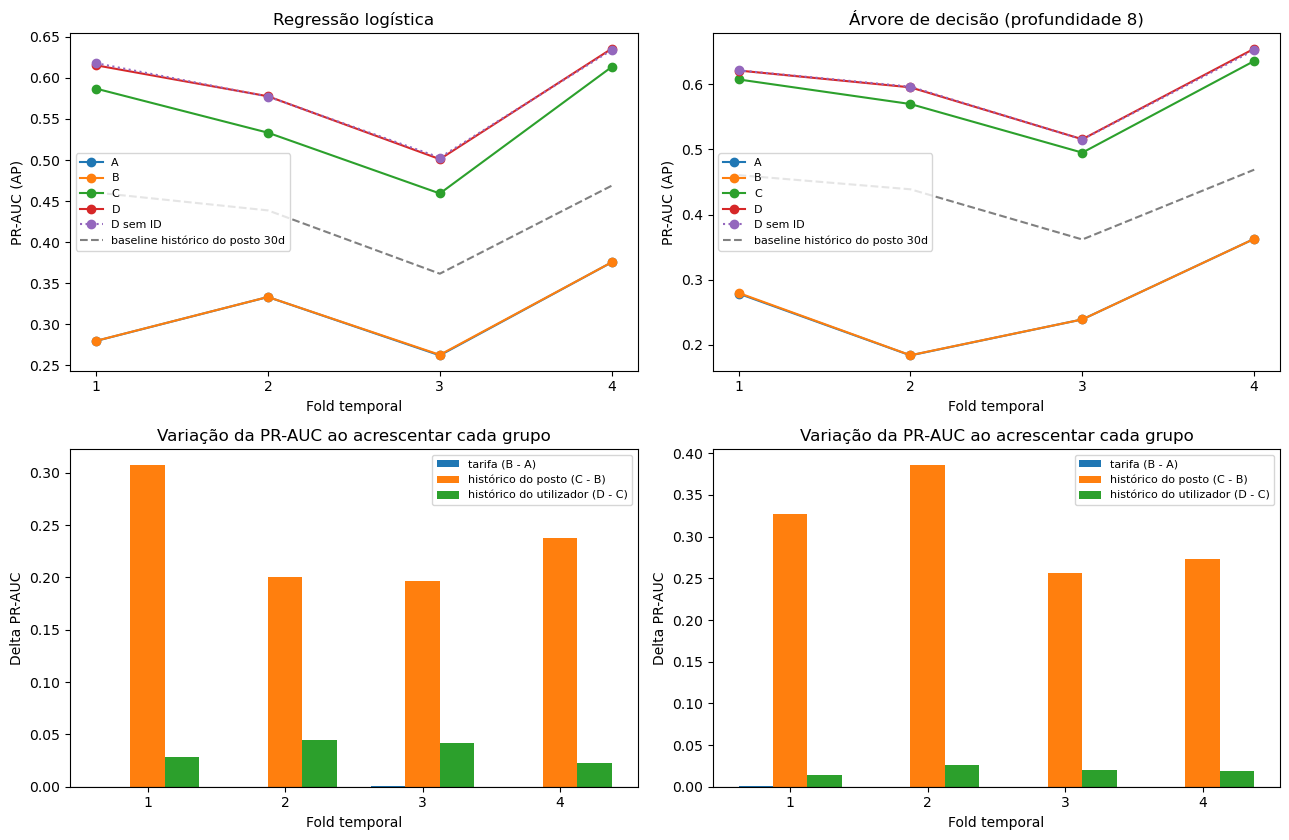

In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, len(MODELS), figsize=(13, 8.5))
fold_ids = list(range(1, N_FOLDS + 1))
history_line = baselines["Baseline histórico do posto 30d (PR-AUC)"].to_numpy()

for j, model_label in enumerate(MODELS):
    ax = axes[0, j]
    for set_name in variants:
        d = ablation[(ablation["modelo"] == model_label) & (ablation["conjunto"] == set_name)]
        ax.plot(d["fold"], d["PR-AUC (AP)"], marker="o", ls=":" if set_name == "D sem ID" else "-", label=set_name)
    ax.plot(fold_ids, history_line, ls="--", color="gray", label="baseline histórico do posto 30d")
    ax.set(title=model_label, xlabel="Fold temporal", ylabel="PR-AUC (AP)", xticks=fold_ids)
    ax.legend(fontsize=8)

    ax = axes[1, j]
    width = 0.25
    for i, (effect, bigger, smaller) in enumerate(EFFECTS[:3]):
        d = paired_delta(model_label, bigger, smaller)
        ax.bar(np.array(d.index) + (i - 1) * width, d.values, width, label=effect)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(title="Variação da PR-AUC ao acrescentar cada grupo", xlabel="Fold temporal",
           ylabel="Delta PR-AUC", xticks=fold_ids)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### 4. Arranque a frio e identificador do posto

A tabela mostra que parte das sessões de validação são casos sem histórico. "Utilizadores novos" usa `is_new_user` (primeira sessão do utilizador em todo o histórico). "Utilizadores sem sessões no treino do fold" é maior porque inclui utilizadores cuja primeira sessão ocorreu mais cedo na própria janela de validação: nas sessões seguintes já existe histórico disponível no momento da previsão. Depois compara-se a PR-AUC do conjunto D em utilizadores novos e existentes.

In [40]:
is_new = (X["is_new_user"].to_numpy() == 1)
no_post_history = (X["post_no_previous_completed_session"].to_numpy() == 1)
user_ids, post_ids = df["userid"].to_numpy(), df["charging_post_id"].to_numpy()

coverage_rows = []
for k, (train_idx, val_idx) in enumerate(folds, start=1):
    coverage_rows.append({
        "fold": k,
        "utilizadores novos (is_new_user)": is_new[val_idx].mean(),
        "utilizadores sem sessões no treino do fold": (~np.isin(user_ids[val_idx], user_ids[train_idx])).mean(),
        "sem histórico de posto": no_post_history[val_idx].mean(),
        "postos não vistos no treino": (~np.isin(post_ids[val_idx], post_ids[train_idx])).mean(),
        "prevalência (utilizador novo)": y.iloc[val_idx][is_new[val_idx]].mean(),
        "prevalência (utilizador existente)": y.iloc[val_idx][~is_new[val_idx]].mean(),
    })
coverage = pd.DataFrame(coverage_rows).set_index("fold")
print("Casos de arranque a frio nos folds de validação (fração das sessões):")
display(coverage.round(4))

cold_rows = []
for model_label in MODELS:
    for k, (_, val_idx) in enumerate(folds):
        score, y_val, new = ablation_scores[(model_label, "D")][k], y.iloc[val_idx].to_numpy(), is_new[val_idx]
        for group, mask in (("utilizador novo", new), ("utilizador existente", ~new)):
            cold_rows.append({"modelo": model_label, "grupo": group, "fold": k + 1, "n": int(mask.sum()),
                              "PR-AUC": average_precision_score(y_val[mask], score[mask]) if y_val[mask].sum() else np.nan})
cold = pd.DataFrame(cold_rows)
print("PR-AUC do conjunto D por tipo de utilizador (média entre folds):")
display(cold.groupby(["modelo", "grupo"])[["n", "PR-AUC"]].mean().round(3))

Casos de arranque a frio nos folds de validação (fração das sessões):


,utilizadores novos (is_new_user),utilizadores sem sessões no treino do fold,sem histórico de posto,postos não vistos no treino,prevalência (utilizador novo),prevalência (utilizador existente)
fold,,,,,,
1,0.1184,0.3784,0.0,0.0,0.2001,0.1850
2,0.1033,0.3373,0.0,0.0,0.2128,0.1627
3,0.1457,0.4553,0.0,0.0,0.1950,0.1461
4,0.1353,0.4333,0.0,0.0,0.2349,0.1880


PR-AUC do conjunto D por tipo de utilizador (média entre folds):


n  PR-AUC
modelo                             grupo                                 
Regressão logística                utilizador existente  50389.75   0.594
                                   utilizador novo        7160.00   0.505
Árvore de decisão (profundidade 8) utilizador existente  50389.75   0.612
                                   utilizador novo        7160.00   0.478

### 5. Interpretação

**A tarifa acrescenta algo para além da hora do dia?** Não. B - A é +0,0004 (logística) e +0,0003 (árvore) de PR-AUC, e ROC-AUC, Brier e número de alertas ficam praticamente iguais. O sinal muda de fold para fold (na logística é negativo no fold 1) e nunca passa de +0,0011. Dentro do ruído, a tarifa é redundante dado A, o que é consistente com a Task 2.

**Quanto vale o histórico do posto?** É o grupo dominante. C - B é +0,235 (logística) e +0,311 (árvore), positivo em todos os folds e nunca abaixo de +0,197 e +0,256. A PR-AUC média passa de 0,313 para 0,548 (logística) e de 0,266 para 0,577 (árvore). Como A já contém `charging_post_id`, a identidade do posto não explica este ganho. O que conta é o estado recente do posto (taxa de anomalias, tempo desde a última sessão). Sem histórico (A e B) os modelos ficam abaixo do baseline do posto a 30 dias (0,432), embora acima da prevalência (0,176). Com histórico (C e D) superam-no em todos os folds.

**O histórico do utilizador acrescenta algo?** Um pouco, e de forma consistente. D - C é +0,034 (logística) e +0,020 (árvore), positivo em 4 de 4 folds (mínimos +0,022 e +0,014). O F2 sobe de 0,545 para 0,582 (logística) e de 0,564 para 0,582 (árvore), e a precision de 0,404 para 0,447 e de 0,457 para 0,469 ao limiar 0,2. O ganho é entre 7 e 16 vezes menor do que o do posto.

**O efeito é consistente entre folds?** A ordem A ≈ B < C < D mantém-se em todos os folds e nos dois modelos. O nível absoluto varia (D na logística vai de 0,50 a 0,64, com o fold 3 sempre o mais baixo, tal como o baseline), mas os ganhos de cada grupo têm sempre o mesmo sinal, exceto B - A, que é nulo.

**O modelo depende da identidade do posto?** Não. D - D sem ID é -0,0000 (logística) e +0,0003 (árvore), com ganho em 2 de 4 folds, ou seja, retirar `charging_post_id` não altera o desempenho quando o histórico está presente. `location_information` e `district_name` podem funcionar como identificadores indiretos, por isso a independência do posto não está totalmente demonstrada.

**Arranque a frio.** Os utilizadores novos são 10% a 15% das sessões de validação. Nestes, a PR-AUC do conjunto D é 0,506 (logística) e 0,478 (árvore), contra 0,594 e 0,612 nos utilizadores existentes, apesar de a prevalência ser ligeiramente maior nos novos (0,195 a 0,235). Em todos os folds há histórico de posto e nenhum posto é novo, por isso o desempenho em postos novos não pôde ser medido.

### 6. Discussão operacional e ética

**Dependência do histórico do posto.** O desempenho depende de o registo de causas de fim de sessão estar completo e atualizado. Em produção, o histórico só pode usar sessões já terminadas no momento do início (como no protocolo, com purga). Atrasos ou erros de registo degradam o sinal que mais pesa. Um posto sem sessões também não gera histórico e fica invisível para o modelo.

**Utilização dos alertas.** Ao limiar provisório 0,2 há cerca de 230 a 260 alertas por 1000 sessões nos conjuntos C e D, com precision entre 0,40 e 0,47. Mais de metade dos alertas são falsos alarmes, o que tem custo operacional. O limiar deve ser fixado com o custo real de falso negativo e falso positivo.

**Dados pessoais.** O histórico do utilizador baseia-se em `userid` e constrói um perfil individual de comportamento. Levanta questões de proteção de dados (minimização, finalidade, base legal, pseudonimização), para um ganho pequeno (+0,020 a +0,034 de PR-AUC). O conjunto C (sem histórico do utilizador) perde 0,035 (logística) e 0,020 (árvore) de PR-AUC média face a D, e é a alternativa sem perfis individuais. A escolha final cabe ao grupo.

**Risco de culpabilizar o utilizador.** Uma taxa de anomalias elevada num utilizador pode refletir o posto, o veículo ou o local, e não o comportamento. O modelo não deve levar a bloquear, limitar ou penalizar clientes. O uso adequado é priorizar verificações e manutenção dos postos.

**Arranque a frio e generalização.** Para utilizadores novos o desempenho desce (secção 4). Para postos novos não há evidência nos dados. Como retirar o identificador do posto não custa PR-AUC, o modelo sem ID é preferível para os generalizar, com o conjunto A ou a média da rede como alternativa enquanto o histórico não existe.

**Variação ao longo do tempo.** O nível de desempenho muda entre folds e o histórico a 30 dias adapta-se ao estado atual dos postos, mas o limiar e o modelo devem ser monitorizados e reavaliados periodicamente.

### 7. Limitações

- Os mesmos 4 folds servem para escolher a profundidade da árvore e para esta ablação, e a profundidade foi escolhida com todas as colunas.
- Com 4 folds, "4 de 4" descreve consistência, não significância estatística. Diferenças muito pequenas (B - A e D - D sem ID) devem ler-se como ausência de efeito detetável, não como prova de efeito nulo.
- As métricas ao limiar 0,2 mudam quando o limiar definitivo for fixado.
- A ablação é em camadas, por isso o contributo medido de cada grupo depende da ordem. Em particular, o histórico do utilizador foi medido depois do histórico do posto e não isoladamente.
- O teste final (a partir de 2021-08-01) não foi usado.

## 3.4 Ensemble Models

### Experimental protocol

Os modelos ensemble são avaliados nas mesmas condições experimentais dos modelos individuais, utilizando o feature set D, o mesmo target e o mesmo limiar provisório de 0,2. A avaliação utiliza os mesmos quatro folds temporais em expanding window: em cada fold, o modelo é treinado apenas com observações anteriores ao período de validação, aumentando progressivamente a janela de treino. É também mantido o período de purga entre treino e validação, reduzindo o risco de leakage temporal.

Todo o preprocessing é aprendido exclusivamente a partir dos dados de treino de cada fold. O final test, definido a partir de `TEST_START`, permanece completamente reservado e não é utilizado para selecionar, comparar ou configurar modelos. Não é utilizado *random split* nem validação cruzada aleatória, uma vez que estas abordagens poderiam quebrar a ordem temporal dos dados. A otimização de hiperparâmetros e a seleção do limiar final ficam reservadas para a Task 4.

Foram selecionados três ensembles que representam princípios de combinação distintos, permitindo avaliar diferentes formas de melhorar os modelos individuais:

- **Random Forest (Bagging):** escolhida por partir do mesmo princípio das Decision Trees, que já apresentaram um desempenho competitivo, mas reduzindo a dependência de uma única árvore. Combina múltiplas árvores treinadas sobre amostras *bootstrap* e subconjuntos aleatórios de features. Esta diversidade e posterior agregação procuram reduzir a instabilidade e a variância de uma Decision Tree individual.

- **HistGradientBoosting (Boosting):** escolhido para representar uma estratégia sequencial, distinta do bagging. Os learners são construídos progressivamente, permitindo ao ensemble melhorar os erros dos modelos anteriores e captar relações não lineares e interações entre as features.

- **Soft Voting (combinação heterogénea):** escolhido para avaliar se modelos de diferentes famílias podem complementar-se. Os modelos são treinados independentemente e as suas probabilidades são agregadas. Como diferentes algoritmos podem captar padrões distintos e cometer erros diferentes, a combinação pode produzir previsões mais robustas do que as dos constituintes individuais.

### Random Forest e Boosting

A **Random Forest** utiliza uma configuração inicial fixa com `n_estimators=100`. O parâmetro `min_samples_leaf` é mantido igual ao utilizado na Decision Tree de referência, não tendo sido otimizado especificamente para a Random Forest. A otimização dos hiperparâmetros fica reservada para a Task 4.

Para **Boosting**, utiliza-se o `HistGradientBoostingClassifier`, também com uma configuração inicial fixa. A representação utilizada mantém as 40 features originais após imputação e codificação, evitando a criação de uma matriz *one-hot* potencialmente muito maior.

Em ambos os modelos, as variáveis categóricas são transformadas com `OrdinalEncoder`, permitindo uma representação densa e computacionalmente eficiente. No entanto, esta opção apresenta uma limitação: os valores atribuídos às categorias não representam uma ordem real, podendo os modelos baseados em árvores criar divisões influenciadas por essa codificação artificial.

In [ ]:
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    VotingClassifier,
)

# preparação de dados para o modelo Random Forest e Boosting
def ensemble_tree_preprocessor():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric_cols),
        (
            "cat",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ),
            CATEGORICAL,
        ),
    ])

# construção do random forest
def make_random_forest():
    clf = RandomForestClassifier(
        n_estimators=100, #100 árvores
        min_samples_leaf=TREE_MIN_SAMPLES_LEAF, #mínimo de amostras por folha
        random_state=RANDOM_STATE, #estado aleatório para reprodutibilidade
        n_jobs=-1, #usar todos os núcleos disponíveis para paralelização
    )

    # Pipeline que combina o pré-processamento e o classificador
    return Pipeline([
        ("prep", ensemble_tree_preprocessor()),
        ("clf", clf),
    ])


def make_boosting():
    clf = HistGradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
    return Pipeline([
        ("prep", ensemble_tree_preprocessor()),
        ("clf", clf),
    ])


# Construção do ensemble Voting com os dois modelos individuais mais fortes
def make_voting():
    return VotingClassifier(
        estimators=[
            ("logistic", make_logistic()),
            ("tree", make_tree(chosen_depth)),
        ],
        voting="soft", #soft voting, que combina as probabilidades previstas pelos modelos individuais
    )

# Construção do ensemble Voting com os dois modelos individuais mais fortes e Random Forest
def make_voting_with_rf():
    """Variante exploratória que acrescenta Random Forest."""
    return VotingClassifier(
        estimators=[
            ("logistic", make_logistic()),
            ("tree", make_tree(chosen_depth)),
            ("random_forest", make_random_forest()),
        ],
        voting="soft",
    )

# pega num modelo de ensemble e faz cross-validation, retornando as previsões e o tempo médio de ajuste
def cross_val_predict_ensemble(make_model):
    predictions = []
    fit_seconds = []

    for train_idx, val_idx in folds:
        started = time.perf_counter()

        model = make_model()
        model.fit(X.iloc[train_idx], y.iloc[train_idx]) #ajusta o modelo com os dados de treino do fold atual

        fit_seconds.append(time.perf_counter() - started)

        scores = model.predict_proba(X.iloc[val_idx])[:, 1] #para os dados de validação, calcula a probabilidade de pertencer à classe 1 = anormal.
        predictions.append(scores)

    return {
        "pred": predictions,
        "fit_s": float(np.mean(fit_seconds)),
        "fit_s_by_fold": fit_seconds,
    }


# Apenas duas variantes de Voting são avaliadas.
# Esta é uma comparação exploratória limitada e não uma pesquisa
# extensiva de configurações.
voting_variants = {
    "Voting (Logistic + Tree)": cross_val_predict_ensemble(make_voting),
    "Voting (Logistic + Tree + RF)": cross_val_predict_ensemble(
        make_voting_with_rf
    ),
}


# Verificações básicas das previsões.
for name, result in voting_variants.items():
    assert [len(p) for p in result["pred"]] == [
        len(val_idx) for _, val_idx in folds
    ], name

    assert all(
        np.isfinite(p).all()
        and p.min() >= 0
        and p.max() <= 1
        for p in result["pred"]
    ), name


# Avaliação das duas variantes.
voting_variant_rows = []

for model_name, result in voting_variants.items():
    for k, ((_, val_idx), score, fit_s) in enumerate(
        zip(folds, result["pred"], result["fit_s_by_fold"]),
        start=1,
    ):
        voting_variant_rows.append({
            "modelo": model_name,
            "fold": k,
            "Time (s)": fit_s,
            **evaluate_fold(
                y.iloc[val_idx].to_numpy(),
                score
            ),
        })


voting_variant_per_fold = pd.DataFrame(voting_variant_rows)

voting_variant_mean = (
    voting_variant_per_fold
    .groupby("modelo")[METRICS + ["Time (s)"]]
    .mean()
)

voting_variant_std = (
    voting_variant_per_fold
    .groupby("modelo")[METRICS]
    .std(ddof=1)
)

voting_variant_summary = voting_variant_mean.join(
    voting_variant_std.add_suffix(" std")
)


# Escolha exploratória da variante principal exclusivamente com
# base nos folds de desenvolvimento.
# entre as duas variantes de Voting, qual tem a maior PR-AUC média?
principal_voting_name = (
    voting_variant_mean["PR-AUC (AP)"].idxmax()
)


# Avaliação dos três princípios de ensemble.
ensemble_models = {
    "Random Forest": cross_val_predict_ensemble(make_random_forest),
    "Boosting (HistGradientBoosting)": cross_val_predict_ensemble(
        make_boosting
    ),
    principal_voting_name: voting_variants[principal_voting_name],
}


ensemble_overview = pd.DataFrame({
    "princípio": [
        "Bagging / random feature subsampling",
        "Boosting sequencial",
        "Combinação heterogénea estática",
    ],
    "folds ajustados": [
        len(result["pred"])
        for result in ensemble_models.values()
    ],
    "tempo médio de ajuste por fold (s)": [
        result["fit_s"]
        for result in ensemble_models.values()
    ],
    "probabilidade mínima": [
        min(p.min() for p in result["pred"])
        for result in ensemble_models.values()
    ],
    "probabilidade máxima": [
        max(p.max() for p in result["pred"])
        for result in ensemble_models.values()
    ],
}, index=list(ensemble_models))


print("Comparação exploratória das duas variantes de Voting:")
display(voting_variant_summary.round(4))

print(f"Voting principal escolhido: {principal_voting_name}")

display(ensemble_overview.round(4))

c:\Users\ritav\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] O sistema não conseguiu localizar o ficheiro especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\ritav\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\ritav\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ritav\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\ritav\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _

Comparação exploratória das duas variantes de Voting:


,PR-AUC (AP),Precision,Recall,F1,F2,ROC-AUC,Brier,Alertas por 1000,Time (s),PR-AUC (AP) std,Precision std,Recall std,F1 std,F2 std,ROC-AUC std,Brier std,Alertas por 1000 std
modelo,,,,,,,,,,,,,,,,,
Voting (Logistic + Tree + RF),0.6128,0.4555,0.6545,0.5371,0.6019,0.8348,0.1009,252.4201,17.1855,0.0581,0.0315,0.0516,0.0389,0.0456,0.0121,0.0030,30.0504
Voting (Logistic + Tree),0.6077,0.4593,0.6401,0.5348,0.5933,0.8318,0.1014,244.7745,8.5345,0.0583,0.0346,0.0515,0.0409,0.0465,0.0118,0.0031,28.2920


Voting principal escolhido: Voting (Logistic + Tree + RF)


,princípio,folds ajustados,tempo médio de ajuste por fold (s),probabilidade mínima,probabilidade máxima
Random Forest,Bagging / random feature subsampling,4,7.7794,0.0036,0.9656
Boosting (HistGradientBoosting),Boosting sequencial,4,3.1736,0.0046,0.9912
Voting (Logistic + Tree + RF),Combinação heterogénea estática,4,17.1855,0.0091,0.9734


### Voting: escolha exploratória da composição

Foram avaliadas duas composições de Soft Voting utilizando os mesmos folds temporais:

- **Voting A:** Logistic Regression + Decision Tree;
- **Voting B:** Logistic Regression + Decision Tree + Random Forest.

O **Naive Bayes** não foi incluído no Voting por apresentar a menor PR-AUC entre os modelos individuais e um comportamento menos favorável das probabilidades, incluindo um Brier Score superior e maior concentração em valores extremos. Como o Soft Voting combina diretamente as probabilidades dos modelos, a sua inclusão poderia prejudicar a combinação.

A variante com maior PR-AUC média nos folds de desenvolvimento é utilizada como Voting principal. Esta comparação é limitada às duas composições definidas e o final test não participa nesta escolha.

Foi utilizado **Soft Voting**, combinando as probabilidades produzidas pelos modelos em vez das classes previstas diretamente.

In [ ]:
#avaliar e organizar os resultados
ensemble_rows = []
for model_name, result in ensemble_models.items():
    for k, ((_, val_idx), score, fit_s) in enumerate(zip(folds, result["pred"], result["fit_s_by_fold"]), start=1):
        ensemble_rows.append({"modelo": model_name, "fold": k, "Time (s)": fit_s,
                              **evaluate_fold(y.iloc[val_idx].to_numpy(), score)})
ensemble_per_fold = pd.DataFrame(ensemble_rows)
ensemble_mean = ensemble_per_fold.groupby("modelo")[METRICS + ["Time (s)"]].mean()
ensemble_std = ensemble_per_fold.groupby("modelo")[METRICS].std(ddof=1)
ensemble_summary = ensemble_mean.join(ensemble_std.add_suffix(" std"))
print("Resultados dos ensembles por fold:")
display(ensemble_per_fold.set_index(["modelo", "fold"]).round(4))
print("Resumo dos ensembles ((média e desvio-padrão entre folds):")
display(ensemble_summary.round(4))

Resultados dos ensembles por fold:


Time (s)  PR-AUC (AP)  Precision  \
modelo                          fold                                     
Random Forest                   1       2.4106       0.6429     0.4641   
                                2       5.9711       0.6094     0.4421   
                                3       9.6164       0.5327     0.4010   
                                4      13.1195       0.6644     0.4618   
Boosting (HistGradientBoosting) 1       2.2346       0.6515     0.4913   
                                2       3.0392       0.6130     0.4546   
                                3       3.4690       0.5453     0.4222   
                                4       3.9515       0.6714     0.4858   
Voting (Logistic + Tree + RF)   1      12.2242       0.6425     0.4771   
                                2      13.4151       0.6101     0.4532   
                                3      18.9203       0.5326     0.4118   
                                4      24.1826       0.6659     0.4799   

                                      Recall      F1      F2  ROC-AUC   Brier  \
modelo                          fold                                            
Random Forest                   1     0.7105  0.5615  0.6423   0.8448  0.1029   
                                2     0.6465  0.5251  0.5918   0.8331  0.0988   
                                3     0.6124  0.4846  0.5540   0.8187  0.0984   
                                4     0.7195  0.5625  0.6473   0.8460  0.1042   
Boosting (HistGradientBoosting) 1     0.6802  0.5705  0.6316   0.8447  0.1014   
                                2     0.6257  0.5266  0.5819   0.8297  0.0978   
                                3     0.5890  0.4919  0.5459   0.8210  0.0972   
                                4     0.6979  0.5729  0.6419   0.8465  0.1030   
Voting (Logistic + Tree + RF)   1     0.6942  0.5655  0.6363   0.8425  0.1029   
                                2     0.6298  0.5271  0.5843   0.8320  0.0984   
                                3     0.5937  0.4863  0.5455   0.8190  0.0983   
                                4     0.7003  0.5695  0.6414   0.8457  0.1039   

                                      Alertas por 1000  
modelo                          fold                    
Random Forest                   1             285.9868  
                                2             245.5854  
                                3             233.9709  
                                4             302.7811  
Boosting (HistGradientBoosting) 1             258.6418  
                                2             231.1361  
                                3             213.7050  
                                4             279.1894  
Voting (Logistic + Tree + RF)   1             271.8450  
                                2             233.3631  
                                3             220.8633  
                                4             283.6090

Resumo dos ensembles ((média e desvio-padrão entre folds):


,PR-AUC (AP),Precision,Recall,F1,F2,ROC-AUC,Brier,Alertas por 1000,Time (s),PR-AUC (AP) std,Precision std,Recall std,F1 std,F2 std,ROC-AUC std,Brier std,Alertas por 1000 std
modelo,,,,,,,,,,,,,,,,,
Boosting (HistGradientBoosting),0.6203,0.4635,0.6482,0.5405,0.6003,0.8355,0.0999,245.6681,3.1736,0.0556,0.0319,0.0500,0.0387,0.0447,0.0122,0.0028,29.0104
Random Forest,0.6124,0.4422,0.6722,0.5334,0.6088,0.8356,0.1011,267.0811,7.7794,0.0577,0.0292,0.0514,0.0369,0.0443,0.0127,0.0029,32.6101
Voting (Logistic + Tree + RF),0.6128,0.4555,0.6545,0.5371,0.6019,0.8348,0.1009,252.4201,17.1855,0.0581,0.0315,0.0516,0.0389,0.0456,0.0121,0.0030,30.0504


## 3.5 Global Model Comparison

Os três ensembles são agora comparados diretamente com os três modelos individuais desenvolvidos anteriormente:

- Logistic Regression;
- Gaussian Naive Bayes;
- Decision Tree;
- Random Forest;
- HistGradientBoosting;
- Voting.

Todos os modelos são avaliados nos mesmos folds temporais, com o mesmo conjunto de features D e as mesmas métricas. A PR-AUC é utilizada como principal critério de comparação devido ao desequilíbrio da classe positiva.

A comparação não considera apenas a média: são também analisadas a variabilidade entre períodos, Precision, Recall, F1, F2, custo computacional e interpretabilidade.

O final test permanece completamente intocado.

,PR-AUC (AP),Precision,Recall,F1,F2,ROC-AUC,Brier,Alertas por 1000,Time (s),PR-AUC (AP) std,Precision std,Recall std,F1 std,F2 std,ROC-AUC std,Brier std,Alertas por 1000 std
modelo,,,,,,,,,,,,,,,,,
Boosting (HistGradientBoosting),0.6203,0.4635,0.6482,0.5405,0.6003,0.8355,0.0999,245.6681,3.1736,0.0556,0.0319,0.0500,0.0387,0.0447,0.0122,0.0028,29.0104
Voting (Logistic + Tree + RF),0.6128,0.4555,0.6545,0.5371,0.6019,0.8348,0.1009,252.4201,17.1855,0.0581,0.0315,0.0516,0.0389,0.0456,0.0121,0.0030,30.0504
Random Forest,0.6124,0.4422,0.6722,0.5334,0.6088,0.8356,0.1011,267.0811,7.7794,0.0577,0.0292,0.0514,0.0369,0.0443,0.0127,0.0029,32.6101
Árvore de decisão (profundidade 8),0.5966,0.4687,0.6207,0.5336,0.5825,0.8256,0.1021,233.3516,2.9196,0.0592,0.0296,0.0644,0.0400,0.0524,0.0127,0.0033,39.0139
Regressão logística,0.5824,0.4476,0.6299,0.5232,0.5823,0.8208,0.1046,247.0056,5.1915,0.0593,0.0392,0.0421,0.0409,0.0417,0.0122,0.0034,21.3024
Naive Bayes,0.5172,0.4373,0.5732,0.4948,0.5386,0.7874,0.1747,231.7344,0.8934,0.0509,0.0350,0.0823,0.0462,0.0641,0.0133,0.0171,49.3662


modelo,Boosting (HistGradientBoosting),Naive Bayes,Random Forest,Regressão logística,Voting (Logistic + Tree + RF),Árvore de decisão (profundidade 8)
fold,,,,,,
1,0.6515,0.5369,0.6429,0.6153,0.6425,0.6210
2,0.6130,0.5270,0.6094,0.5776,0.6101,0.5952
3,0.5453,0.4439,0.5327,0.5011,0.5326,0.5155
4,0.6714,0.5610,0.6644,0.6356,0.6659,0.6545


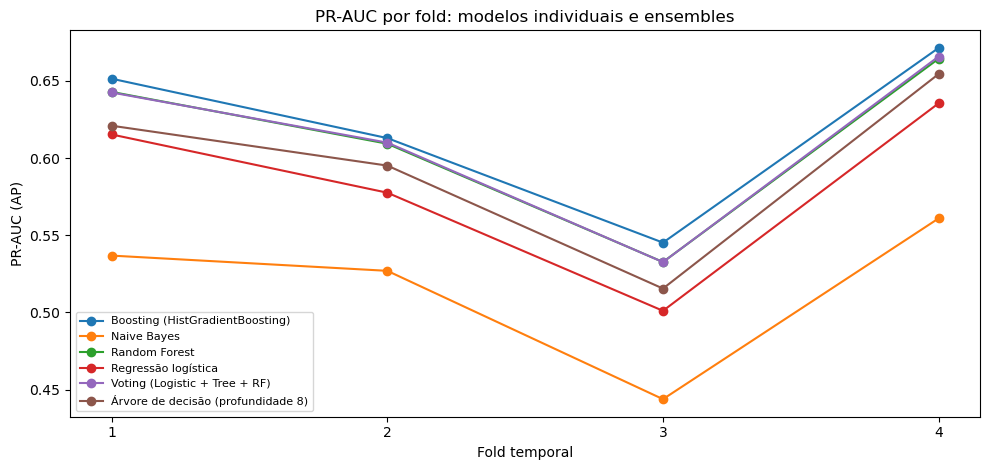

In [43]:
individual_rows = []
for model_name, result in individual_models.items():
    for k, ((_, val_idx), score) in enumerate(zip(folds, result["pred"]), start=1):
        individual_rows.append({"modelo": model_name, "fold": k, "Time (s)": result["fit_s"],
                                **evaluate_fold(y.iloc[val_idx].to_numpy(), score)})

all_per_fold = pd.concat([pd.DataFrame(individual_rows), ensemble_per_fold], ignore_index=True)
all_mean = all_per_fold.groupby("modelo")[METRICS + ["Time (s)"]].mean()
all_std = all_per_fold.groupby("modelo")[METRICS].std(ddof=1)
all_summary = all_mean.join(all_std.add_suffix(" std")).sort_values("PR-AUC (AP)", ascending=False)

display(all_summary.round(4))
pr_fold_all = all_per_fold.pivot(index="fold", columns="modelo", values="PR-AUC (AP)")
display(pr_fold_all.round(4))
fig, ax = plt.subplots(figsize=(10, 4.8))
for model_name in pr_fold_all.columns:
    ax.plot(pr_fold_all.index, pr_fold_all[model_name], marker="o", label=model_name)
ax.set(xlabel="Fold temporal", ylabel="PR-AUC (AP)", title="PR-AUC por fold: modelos individuais e ensembles", xticks=list(pr_fold_all.index))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Análise dos resultados

#### Random Forest vs Decision Tree

A Random Forest apresentou uma melhoria consistente relativamente à Decision Tree individual. A PR-AUC média aumentou de **0,5966 para 0,6124**, correspondendo a um ganho de **0,0158**, e a Random Forest foi superior nos **4 folds temporais**. O desvio-padrão da PR-AUC também diminuiu ligeiramente, de **0,0592 para 0,0577**.

Estes resultados são compatíveis com o efeito esperado do bagging e da feature subsampling, uma vez que a combinação de várias árvores pode reduzir a variância associada a uma única Decision Tree. No entanto, a pequena diferença de desvio-padrão observada não é suficiente para afirmar uma redução estatisticamente significativa da variabilidade temporal.

A melhoria teve também um custo computacional: o tempo médio de ajuste aumentou de **2,92 s por fold** na Decision Tree para **7,78 s por fold** na Random Forest.

#### Boosting

O HistGradientBoosting apresentou a **maior PR-AUC média de todos os modelos avaliados (0,6203)**, superando a Decision Tree em **0,0237** e apresentando melhor PR-AUC nos **4 folds temporais**.

O seu desvio-padrão de PR-AUC foi **0,0556**, ligeiramente inferior aos valores da Random Forest (0,0577) e da Decision Tree (0,0592). Assim, além da melhor performance média, o Boosting apresentou uma variabilidade temporal ligeiramente inferior entre estes modelos.

O tempo médio de ajuste foi de **3,17 s por fold**, inferior aos **7,78 s** da Random Forest. Neste dataset e com as configurações iniciais utilizadas, o Boosting apresentou portanto o melhor compromisso entre PR-AUC, consistência temporal e custo computacional entre os ensembles avaliados.

#### Bagging vs Boosting

Os resultados mostram que ambos os princípios de ensemble melhoraram a Decision Tree individual, mas o Boosting apresentou vantagem sobre a Random Forest em PR-AUC média (**0,6203 vs 0,6124**) e menor tempo médio de ajuste (**3,17 s vs 7,78 s**).

A Random Forest cria diversidade através de bootstrap sampling e feature subsampling, combinando árvores treinadas de forma essencialmente independente. O Boosting, por outro lado, constrói learners sequencialmente, permitindo que o ensemble refine progressivamente os erros dos modelos anteriores.

Neste dataset, a abordagem sequencial apresentou melhor capacidade discriminativa média, embora a Random Forest tenha alcançado o maior F2 entre todos os modelos (**0,6088**), refletindo o seu recall mais elevado (**0,6722**) com o limiar provisório utilizado.

#### Voting

Entre as duas composições exploratórias, o Soft Voting constituído por **Logistic Regression + Decision Tree + Random Forest** apresentou maior PR-AUC média (**0,6128**) do que a combinação Logistic Regression + Decision Tree (**0,6077**) e foi, por isso, selecionado como variante principal.

O Voting principal superou a Logistic Regression em **0,0304** de PR-AUC e a Decision Tree em **0,0162**, sendo superior a ambos nos **4 folds temporais**. Isto mostra que a combinação heterogénea conseguiu beneficiar da diversidade entre os modelos constituintes.

Contudo, o Voting não superou o Boosting e apresentou uma PR-AUC apenas marginalmente superior à Random Forest (**0,6128 vs 0,6124**). Além disso, teve o maior custo computacional dos ensembles, com **17,19 s por fold**, uma vez que necessita de ajustar e executar vários pipelines. Assim, o ganho obtido pela combinação não parece compensar a complexidade adicional face aos ensembles individuais mais fortes.

#### Estabilidade temporal

O **Fold 3** foi o período mais difícil para os modelos, apresentando as menores PR-AUCs de forma generalizada. Por exemplo, neste fold a PR-AUC foi **0,5453** para Boosting, **0,5327** para Random Forest e **0,5326** para Voting, enquanto nos restantes períodos os valores foram superiores.

O Naive Bayes apresentou o menor desvio-padrão absoluto de PR-AUC (**0,0509**), mas também apresentou a menor PR-AUC média (**0,5172**). Por esse motivo, o menor desvio-padrão isoladamente não deve ser interpretado como evidência de que é o modelo mais robusto ou adequado. Entre os modelos com melhor capacidade preditiva, o Boosting apresentou a maior PR-AUC média e variabilidade temporal relativamente baixa (**0,6203 ± 0,0556**).

De forma geral, as melhorias da Random Forest e do Boosting relativamente à Decision Tree foram observadas nos quatro períodos temporais, indicando que os ganhos não resultam apenas de um único fold.

#### Performance, interpretabilidade e custo

Existe um compromisso claro entre complexidade e interpretabilidade. A Logistic Regression continua a oferecer uma solução relativamente simples e interpretável, embora com PR-AUC inferior aos ensembles. A Decision Tree mantém alguma interpretabilidade através das suas regras, mas foi consistentemente superada pela Random Forest e pelo Boosting.

A Random Forest e o Boosting oferecem melhor performance à custa de menor interpretabilidade. Entre estes, o Boosting apresentou a melhor PR-AUC e um custo de treino inferior ao da Random Forest. O Voting aumentou ainda mais a complexidade operacional e computacional sem produzir uma melhoria relevante sobre os melhores ensembles individuais.

O Naive Bayes foi o modelo mais rápido, mas apresentou a pior PR-AUC e o maior Brier score, tornando-o menos competitivo neste problema.